In [2]:
"""🗓️ План на неделю: от теории к практике
День 1. База: что вообще происходит и как это оценивать
Начните с самых основ, без которых остальное будет непонятно.
Что такое отбор признаков (feature selection) и зачем он нужен? Три подхода: filter (оцениваем признаки до модели), wrapper (используем модель, чтобы перебирать признаки), embedded (модель сама зануляет ненужные коэффициенты).
Почему ROC-AUC, а не accuracy? Accuracy может быть обманчива при несбалансированных классах или когда важно ранжирование. ROC-AUC показывает, насколько хорошо модель разделяет классы на разных порогах. Прочитайте про это 10–15 минут.
Ключевое понятие: утечка данных (data leakage). Это когда при подготовке признаков (например, отборе) вы «подсматриваете» в тестовые или валидационные данные. Из-за этого оценка качества становится завышенной. В этой работе есть отдельное задание про утечку — ему стоит уделить особое внимание.
День 2. Задания 1 и 2.1: базовая модель, дисперсия и корреляция
Задание 1: просто запустите готовый код. Разберитесь, что делает Pipeline (последовательно применяет StandardScaler и LogisticRegression), что такое cross_val_score и почему cv=CV с StratifiedKFold — это правильный способ честной оценки. Ответ на вопрос про accuracy: «Accuracy не показывает, насколько уверенно модель отличает классы, и может вводить в заблуждение, если классы неравны или цена ошибок разная».
Задание 2.1:
VarianceThreshold удалит константный признак — это просто.
Корреляция >0.95: посмотрите на матрицу корреляций. Функция drop_correlated_features должна проходить по верхнему треугольнику и удалять один из пары коррелированных признаков. Подумайте, почему просто выбросить один из двух — не всегда единственно верное решение (ответ: коррелированные признаки могут нести разную информацию в сочетании с другими, или быть полезными для нелинейных моделей).
День 3. Задание 2.2: статистический отбор (ANOVA и Mutual Information)
Это самое объёмное задание, но очень показательное.
f_classif (ANOVA F-test) измеряет линейную связь между признаком и целевой переменной. Он может не заметить сложную нелинейную зависимость.
mutual_info_classif (взаимная информация) улавливает любую зависимость, но работает менее стабильно и требует больше данных.
Что делать: напишите цикл по k и двум score_func. Постройте график ROC-AUC(k). Обратите внимание: на графике качество может выйти на плато — это значит, что дальнейшее добавление признаков не помогает.
Ответ на вопрос про разное ранжирование: «ANOVA ищет только линейные различия в средних, а MI — любую статистическую зависимость. Поэтому признаки, связанные с целью нелинейно, MI может оценить выше, а f_classif — проигнорировать».
День 4. Задание 3: RFE (Wrapper)
RFE рекурсивно удаляет наименее важные признаки, переобучая модель на каждом шаге. Это мощно, но дорого.
Запустите RFE для 5, 10, 20 признаков с step=5. Сравните время с filter-методами — вы увидите, что RFE работает дольше.
Почему RFE нестабилен с коррелированными признаками? Если два признака почти одинаково полезны, модель может на одном шаге опереться на один, на другом — на другой. Поэтому выбранный набор может «прыгать» от фолда к фолду. Это нормально, и в задании 7 вы это измерите.
День 5. Задание 4: L1-регуляризация (Embedded)
L1 (Lasso) штрафует модель за большие коэффициенты и зануляет часть из них. Чем меньше C, тем сильнее штраф и тем меньше признаков остаётся.
Запустите SelectFromModel с LogisticRegression(penalty='l1', solver='liblinear') для C = [0.01, 0.1, 1, 10]. Постройте график «C vs число признаков».
Почему L1 выбирает один из коррелированных признаков «произвольно»? Потому что если два признака дают почти одинаковый вклад, регуляризация может обнулить один и оставить другой — какой именно, зависит от небольших случайностей в данных. Это тоже проявление нестабильности.
День 6. Задания 5 и 6: честное сравнение и утечка
Задание 5: соберите все методы в одну таблицу. Здесь важно понять: Pipeline с селектором внутри — это единственный честный способ кросс-валидации. Когда вы обучаете Pipeline на всём X_train после CV, чтобы посчитать n_features, — это нормально, потому что вы уже выбрали конфигурацию.
Задание 6 (утечка): это самое важное для понимания. В «плохом» коде SelectKBest обучается на всех данных, включая те, что потом попадут в валидацию. Он «подсматривает» метки валидационных объектов и выбирает признаки, которые случайно с ними коррелируют. Поэтому ROC-AUC получается высоким (например, 0.85) на данных, где сигнала нет. В «хорошем» коде селектор — шаг Pipeline, и на каждом фолде он обучается только на тренировочной части. Тогда ROC-AUC падает до ~0.5. Это и есть суть утечки: информация о тестовых метках просачивается в отбор.
День 7. Задание 7 (устойчивость) и финальный отчёт
Устойчивость (stability): вы берёте 5 подвыборок по 80%, на каждой обучаете только селектор и смотрите, насколько совпадают выбранные наборы. Мера Жаккара = размер пересечения / размер объединения. Если множества совпадают, J=1; если не пересекаются, J=0.
Почему стабильность и качество — разные вещи? Метод может давать высокий ROC-AUC, но каждый раз выбирать разные признаки (например, RFE с коррелированными данными). И наоборот, очень стабильный метод может выбирать неоптимальный набор. В финальном отчёте вы как раз сравните эти свойства.
Финальный отчёт: ответьте на все 7 вопросов, опираясь на числа из ваших экспериментов. Например: «Baseline дал CV AUC 0.99 ± 0.01, лучший filter (MI, k=15) — 0.995 ± 0.008, но разница меньше одного стандартного отклонения, поэтому нельзя уверенно говорить о преимуществе».
"""
"""wtf"""


'wtf'

In [3]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import (
    VarianceThreshold, SelectKBest, f_classif, mutual_info_classif,
    RFE, SelectFromModel
)
from sklearn.metrics import roc_auc_score, classification_report
from functools import partial

In [4]:
# Переменная для генерации случайных чисел
RANDOM_STATE = 42
# Схема кросс-валидации и генерация случайнных чисел
StratifiedKFold(
# Количество фолдов
n_splits=5,
# Перемешивание
shuffle=True,
# Параметр случайности для перемешивания
random_state=RANDOM_STATE)
# Настройка отображения до 40 столбцов
pd.set_option('display.max_columns', 40)

"""Есть набор данных"""
data = load_breast_cancer(as_frame=True)
"""Он был раздёлен на обучающую выборку и целевую переменную для предсказания. Переменные X_train"""
X_original = data.data.copy()
y = data.target.copy()

# Создание случайных чисел
rng = np.random.default_rng(RANDOM_STATE)
# Копирование всех столбцов без целевой переменной
X = X_original.copy()
# Добавление сгенерированных случайнных чисел
for j in range(8):
    # Создание столбца и заполнение по нормальному распределению Гаусса его значением в количестве длинны тренировачных данных
    X[f'noise_{j + 1}'] = rng.normal(size=len(X))

# Создание дополнительных столбцов
X['duplicate_mean_radius'] = X['mean radius'] + rng.normal(0, 0.02, len(X))
X['duplicate_mean_texture'] = X['mean texture'] + rng.normal(0, 0.02, len(X))
X['constant_feature'] = 1.0
# Разделение на тренировочные и валидационные данные
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)


In [5]:
# resume
print("☕")
"""
Признаки это столбцы
wzxdfccadsdshrqepautrjiuth
Строка это объёкт, а у объекта есть признак или по сути свойство с какимто значением.
Синонимы, которые вы встретите: feature, признак, переменная, колонка, атрибут, фактор. В коде это буквально X.columns

Среди столбцов есть шум по типу "noise_1" и constant_feature, которые бесмысленны.
По заданию и нужно выявить только необходимые признаки для правильного обучения с помощью методов, а не вручную.
duplicate_mean_radius, duplicate_mean_texture — 2 почти-дубликата реальных признаков (те же значения + маленький шум).
constant_feature — 1 константа (везде 1.0, никакой информации не несёт).
"""
print(X_train.shape)          # (426, 41) — 426 строк, 41 столбец (признак)
print(list(X_train.columns))  # список всех признаков
X_train.head(3)               # первые 3 строки таблицы
print("Оригинальный набор данных")
print(data.data.shape[0], data.data.shape[1])
data.data.head()
"""🔳Терминология хуже дотерской...
Опухоль — это объект (пациент), а y — его класс (злокачественная / доброкачественная).
Класс — это одно из возможных значений целевой переменной y.
задача бинарной классификации — это значит классов для предсказания ровно два.
Если бы y был, скажем, {'кошка', 'собака', 'птица'} — классов было бы три.
Если бы y был числом (размер опухоли в мм) — это была бы не классификация, а регрессия, и понятия класс там нет.
Классы несбалансированны это значит
что количество объектов со значением целевой переменной например 1 не равно количество объектов со значением целевой переменной 0

Стоит сравнивать модели по метрике ROC-AUC если классы несбалансированны. Если больных людей 30%, а модель всех считает здоровыми, то её аккуратность
будет 70%, потому что именно 70% здоровы, однако это не означает, что новую группу людей модель сможет правильно классифицировать с точностью 70%.

Очистка данных это очищение данных от неинформативных элементов, а подбор признаков это взятие наиболее полезных признаков среди информативных.

Методы подбора признаков
filter - не трогает модель. Быстрый, но менее точный.
wrapper - точный. Но медленее. Обучает модель.
embended - баланс точности и скорости.
Фолд это определённое разделение или разбиение данных
"""
print("🔍⚡")
# С методом filter были убраны шумовые признаки
columns_with_noises = X_train.filter(like="noise")
X_train_clean = X_train.drop(columns=columns_with_noises)
print(X_train_clean.head(4))
# Количество колонок
print(X_train_clean.shape)
"""📝"""

☕
(426, 41)
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'noise_1', 'noise_2', 'noise_3', 'noise_4', 'noise_5', 'noise_6', 'noise_7', 'noise_8', 'duplicate_mean_radius', 'duplicate_mean_texture', 'constant_feature']
Оригинальный набор данных
569 30
🔍⚡
     mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
517        19.89         20.26          130.50     1214.0          0.10370   
287        12.89         13.12           81.89      515.9    

'📝'

In [6]:
# Матрица кореляций но все значения по модулю
corr = X_train_clean.corr().abs()
print(corr)

                         mean radius  mean texture  mean perimeter  mean area  \
mean radius                 1.000000      0.326956        0.997875   0.988667   
mean texture                0.326956      1.000000        0.329590   0.321316   
mean perimeter              0.997875      0.329590        1.000000   0.987645   
mean area                   0.988667      0.321316        0.987645   1.000000   
mean smoothness             0.163974      0.042455        0.201531   0.177509   
mean compactness            0.508447      0.213223        0.559070   0.504337   
mean concavity              0.662470      0.276623        0.702194   0.671188   
mean concave points         0.821610      0.272073        0.850007   0.823343   
mean symmetry               0.142776      0.046871        0.178596   0.146884   
mean fractal dimension      0.321006      0.093514        0.270415   0.286907   
radius error                0.683935      0.246064        0.693439   0.734196   
texture error               

In [7]:
# Стандартное отклонение std . Остаются только те столбцы, чьё стандартное отклонение больше нуля
# Таким образом были удалены столбцы, которые имеют одинаковое значение во всех строках
wtf = X_train.loc[:, # Выбираются все колонки
    X_train.std() > 0] # У которых стандартное отклонение больше 0
print(wtf.shape)

(426, 40)


In [8]:
# Верхний треугольник. Всё значения выше диагонали
# Выбраны все значения где
upper = corr.where(
    # Они соответствуют
    np.triu(
        # Единичная матрица размера кореляционной, но вместо единицы или нуля стоит True или False
        np.ones(corr.shape).astype(bool),
        # не считая позицию k.
        k=1
    )
)
print(upper)

                         mean radius  mean texture  mean perimeter  mean area  \
mean radius                      NaN      0.326956        0.997875   0.988667   
mean texture                     NaN           NaN        0.329590   0.321316   
mean perimeter                   NaN           NaN             NaN   0.987645   
mean area                        NaN           NaN             NaN        NaN   
mean smoothness                  NaN           NaN             NaN        NaN   
mean compactness                 NaN           NaN             NaN        NaN   
mean concavity                   NaN           NaN             NaN        NaN   
mean concave points              NaN           NaN             NaN        NaN   
mean symmetry                    NaN           NaN             NaN        NaN   
mean fractal dimension           NaN           NaN             NaN        NaN   
radius error                     NaN           NaN             NaN        NaN   
texture error               

In [9]:
# Повторение функции any
print(any([False, False, False, False, False, False, False, True]))
print(any([False, False, False, False, False, False, False]))

True
False


In [10]:
# сохраняются все названия колонок
X_train_no_dublicates = [column for column in upper.columns
    # Если среди всех значений каждой колонки выше 0.95
    if (any(upper[column]) > 0.95)]
print(X_train_no_dublicates)
print(len(X_train_no_dublicates))

['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'duplicate_mean_radius', 'duplicate_mean_texture', 'constant_feature']
33


In [11]:
# Все лишние колонки
stup_x = [col for col in X_train.columns if not(  col in X_train_no_dublicates  )]
print(stup_x, len(stup_x), "\n⚡")
# Нужные колонки
stup_x = [col for col in X_train.columns if col in X_train_no_dublicates]
print(stup_x, len(stup_x))

['noise_1', 'noise_2', 'noise_3', 'noise_4', 'noise_5', 'noise_6', 'noise_7', 'noise_8'] 8 
⚡
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'duplicate_mean_radius', 'duplicate_mean_texture', 'constant_feature'] 33


In [12]:
# Наконец подбор признаков с помощью разновидности метода filter под названием SelectKBest

method_подбора_признаков_filter = SelectKBest(
    # Функция метода статистики для оценки каждого признака отдельно при помощи нахождения отличий между классами
    score_func=f_classif,
    # Составить топ столько-то признаков
    k=10
)
method_подбора_признаков_filter

,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function f_c...002446E0B8040>
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",10


In [13]:
# Список действий PiPeLiNe
task_list = Pipeline([
    # Стандартный параметр для масштабирования
    (  "scale", StandardScaler()  ),
    # Выбор самого метода
    (  "select", method_подбора_признаков_filter  ),
    (  "model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)  )
])
task_list

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('select', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function f_c...002446E0B8040>
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",10
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",3000


In [23]:
# Указанное в задание разделение по данным

# Кросс валидация и сбор необходимой статистики по данным с помощью выбранных параметров
scores = cross_val_score(
    # Указывается pipeline или список действий
    task_list,
    X_train, y_train,
    # Фолды или настроенное разделение данных
    cv=CV,
    # Характеристика по которой будет оцениваться качество модели
    scoring='roc_auc'
)

In [15]:
# Превращение списка словарей в таблицу
список_словарей = ({"человека": 2}, {"человека": 2, "педалей": 3}, {"человека": 2, "колёса": 4})
таблица = pd.DataFrame(список_словарей)
таблица

,человека,педалей,колёса
0,2,NaN,NaN
1,2,3.0,NaN
2,2,NaN,4.0


In [16]:
# Решение блин
k = [5, 10, 15, 20, 30]

results = []

for number_k in k:
    method_подбора_признаков_filter = SelectKBest(
        # Функция метода статистики для оценки каждого признака отдельно при помощи нахождения отличий между классами
        score_func=f_classif,
        # Составить топ столько-то признаков
        k=number_k
    )
    
    task_list = Pipeline([
        # Стандартный параметр для масштабирования
        (  "scale", StandardScaler()  ),
        # Выбор самого метода
        (  "select", method_подбора_признаков_filter  ),
        (  "model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)  )
    ])

    scores = cross_val_score(
        # Указывается pipeline или список действий
        task_list,
        X_train, y_train,
        # Фолды или настроенное разделение данных
        cv=CV,
        # Характеристика по которой будет оцениваться качество модели
        scoring='roc_auc'
    )
    round(scores.mean(), 4)

    result = ["ANOVA",
        "k = " + str(number_k),
        str(round(scores.mean(), 4)),
        str(round(scores.std(), 4))
        ]
    
    results.append(result)

    # Второй метод

    method_подбора_признаков_filter = SelectKBest(
        # Функция метода статистики для оценки каждого признака отдельно при помощи нахождения отличий между классами
        score_func=partial(mutual_info_classif, random_state=RANDOM_STATE),
        # Составить топ столько-то признаков
        k=number_k
    )
    
    task_list = Pipeline([
        # Стандартный параметр для масштабирования
        (  "scale", StandardScaler()  ),
        # Выбор самого метода
        (  "select", method_подбора_признаков_filter  ),
        (  "model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)  )
    ])

    scores = cross_val_score(
        # Указывается pipeline или список действий
        task_list,
        X_train, y_train,
        # Фолды или настроенное разделение данных
        cv=CV,
        # Характеристика по которой будет оцениваться качество модели
        scoring='roc_auc'
    )
    round(scores.mean(), 4)

    result = ["MI",
        "k = " + str(number_k),
        str(round(scores.mean(), 4)),
        str(round(scores.std(), 4))
        ]
    
    results.append(result)

print(results)
print(pd.DataFrame(results))

D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning

[['ANOVA', 'k = 5', '0.9864', '0.0101'], ['MI', 'k = 5', '0.9872', '0.0094'], ['ANOVA', 'k = 10', '0.9865', '0.0107'], ['MI', 'k = 10', '0.9869', '0.0101'], ['ANOVA', 'k = 15', '0.9913', '0.0056'], ['MI', 'k = 15', '0.9906', '0.0062'], ['ANOVA', 'k = 20', '0.9965', '0.0042'], ['MI', 'k = 20', '0.996', '0.004'], ['ANOVA', 'k = 30', '0.996', '0.0045'], ['MI', 'k = 30', '0.9958', '0.0048']]
       0       1       2       3
0  ANOVA   k = 5  0.9864  0.0101
1     MI   k = 5  0.9872  0.0094
2  ANOVA  k = 10  0.9865  0.0107
3     MI  k = 10  0.9869  0.0101
4  ANOVA  k = 15  0.9913  0.0056
5     MI  k = 15  0.9906  0.0062
6  ANOVA  k = 20  0.9965  0.0042
7     MI  k = 20   0.996   0.004
8  ANOVA  k = 30   0.996  0.0045
9     MI  k = 30  0.9958  0.0048


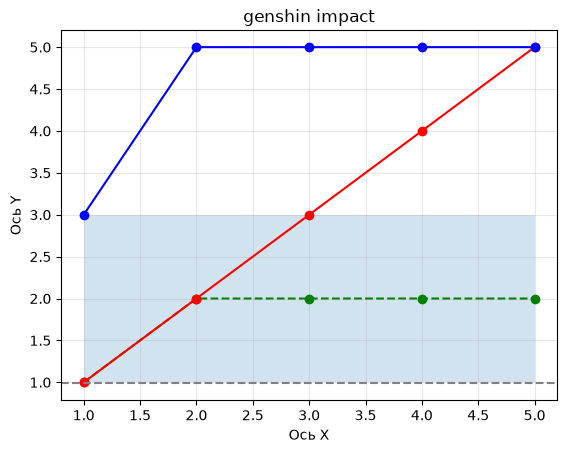

In [17]:
# Создать холст для рисования
plt.figure()

# Одна линия
plt.plot(
    # Координаты точек по x
    [1, 2, 3, 4, 5],
    # Координаты точек по y
    [1, 2, 2, 2, 2],
    # форма точки: 'o' круг, 's' квадрат, '^' треугольник
    marker='o',
    # стиль линии: '-' сплошная, '--' пунктир, ':' точки
    linestyle='--',
    # цвет: 'blue', 'red', 'green' или '#FF0000'
    color='green',
    # label важен: без него plt.legend() не покажет, что какая линия значит.
    label='Моя линия',   # имя для легенды
)

plt.plot(
    # Координаты точек по x
    [1, 2, 3, 4, 5],
    # Координаты точек по y
    [1, 2, 3, 4, 5],
    # форма точки: 'o' круг, 's' квадрат, '^' треугольник
    marker='o',
    # стиль линии: '-' сплошная, '--' пунктир, ':' точки
    linestyle='-',
    # цвет: 'blue', 'red', 'green' или '#FF0000'
    color='red'
)

plt.plot(
    # Координаты точек по x
    [1, 2, 3, 4, 5],
    # Координаты точек по y
    [3, 5, 5, 5, 5],
    # форма точки: 'o' круг, 's' квадрат, '^' треугольник
    marker='o',
    # стиль линии: '-' сплошная, '--' пунктир, ':' точки
    linestyle='-',
    # цвет: 'blue', 'red', 'green' или '#FF0000'
    color='blue'
)

# Заполнение
plt.axhline(y=0.99, color='gray', linestyle='--', label='Baseline')

plt.fill_between(
    # по каким X
    [1, 2, 3, 4, 5],
    # нижняя граница коридора
    [3, 3, 3, 3, 3],
    # верхняя граница
    [1, 1, 1, 1, 1],
    # прозрачность (0 — невидим, 1 — закрашено полностью)
    alpha=0.2,
)

# подпись горизонтальной оси
plt.xlabel('Ось X')
# подпись вертикальной оси
plt.ylabel('Ось Y')
# заголовок графика
plt.title('genshin impact')
# сетка, alpha — прозрачность (0..1)
plt.grid(alpha=0.3)

# Показать
plt.show()

In [18]:
s = [1, 2]
d = ["a", "n"]
print(list(zip(s, d)))

[(1, 'a'), (2, 'n')]


In [19]:
# Подбор признаков через Recursive Feature Elimination
"""
Подбор признаков через постоянное обучение и определение наиболее бесполезных признаков
"""
Recursive_Feature_Elimination = RFE(
    # Модель для подбора
    estimator=LogisticRegression(max_iter=3000, random_state=42),
    # Количество минимального количества самых полезных признаков
    n_features_to_select=10,
    # Максимальное количество признаков для удаления за раз
    step=5,
)

RFE(
    # Модель для подбора
    estimator=LogisticRegression(max_iter=3000, random_state=42),
    # Количество минимального количества самых полезных признаков
    n_features_to_select=10,
    # Максимальное количество признаков для удаления за раз
    step=5,
)


,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).",LogisticRegre...ndom_state=42)
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",10
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",5
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",3000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulati

In [20]:
task_list = Pipeline([
    (  "scale", StandardScaler()  ),
    (  "select", Recursive_Feature_Elimination  ),
    (  "model", LogisticRegression(max_iter=3000, random_state=42)  )
])

Pipeline([
    (  "scale", StandardScaler()  ),
    (  "select", Recursive_Feature_Elimination  ),
    (  "model", LogisticRegression(max_iter=3000, random_state=42)  )
])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('select', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).",LogisticRegre...ndom_state=42)
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",10
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",5
,"verbose verbose: int, default=0Controls verbosity of output.",0


In [21]:
# оценка затраченного времени на процесс
start_time = time.perf_counter()
f = 0
for i in range(30_000_000):
    f += i
end_time = time.perf_counter() - start_time
print(round(end_time, 4), "секунды")

3.1874 секунды


In [32]:
embended_for_features = SelectFromModel(
    LogisticRegression(penalty='l1', solver='liblinear', C=0.1, max_iter=3000, random_state=RANDOM_STATE),    
    threshold=1e-8
)

# Способ подбора признаков Embended
SelectFromModel(
    # Выбор модели для подбора признаков
    LogisticRegression(
        # Способ штрафа модели.
        # L1 это обнуляет ненужные признаки до финального результата. Алгоритм регулирования не подходящих значений.
        penalty='l1',

        # Не обходимый компонент для работы L1
        solver='liblinear',  

        # C=0.1 — обратная сила регуляризации (чем МЕНЬШЕ это число, тем ЖЕСТЧЕ отбор).
        # При C=0.1 штраф за лишние признаки будет сильным. Модель станет "жадной" 
        # и занулит веса у большинства колонок, оставив только самые-самые важные.
        # Предпологаемые значения 0.001, 0.01, 0.1, 1.0, 10.0 могут быть от 0 до бесконечности
        C=0.1,

        # max_iter=3000 — максимальное количество шагов (эпох), которое мы даем 
        # алгоритму, чтобы найти идеальные коэффициенты.
        # чтобы модель точно успела сойтись к правильному решению и не выдала ошибку.
        max_iter=3000,

        # random_state=RANDOM_STATE — фиксируем генератор случайных чисел. 
        # Нужно для того, чтобы при каждом перезапуске ноутбука модель отбирала 
        # абсолютно те же самые колонки (обеспечивает воспроизводимость).
        random_state=RANDOM_STATE
    ),
    
    # threshold=1e-8 — это критерий отбора (порог отсечения признаков).
    # 1e-8 — это число 0.00000001 (практически чистый ноль). 
    # SelectFromModel посмотрит на веса, которые Логистическая Регрессия присвоила колонкам.
    # Если вес колонки по модулю > 0.00000001 — колонка признается важной и остаётся.
    # Если вес ровно 0 (или ничтожно мал) — колонка выкидывается.
    threshold=1e-8
)

,"estimator estimator: objectThe base estimator from which the transformer is built.This can be both a fitted (if ``prefit`` is set to True)or a non-fitted estimator. The estimator should have a``feature_importances_`` or ``coef_`` attribute after fitting.Otherwise, the ``importance_getter`` parameter should be used.",LogisticRegre...r='liblinear')
,"threshold threshold: str or float, default=NoneThe threshold value to use for feature selection. Features whoseabsolute importance value is greater or equal are kept while the othersare discarded. If ""median"" (resp. ""mean""), then the ``threshold`` valueis the median (resp. the mean) of the feature importances. A scalingfactor (e.g., ""1.25*mean"") may also be used. If None and if theestimator has a parameter penalty set to l1, either explicitlyor implicitly (e.g, Lasso), the threshold used is 1e-5.Otherwise, ""mean"" is used by default.",1e-08
,"prefit prefit: bool, default=FalseWhether a prefit model is expected to be passed into the constructordirectly or not.If `True`, `estimator` must be a fitted estimator.If `False`, `estimator` is fitted and updated by calling`fit` and `partial_fit`, respectively.",False
,"norm_order norm_order: non-zero int, inf, -inf, default=1Order of the norm used to filter the vectors of coefficients below``threshold`` in the case where the ``coef_`` attribute of theestimator is of dimension 2.",1
,"max_features max_features: int, callable, default=NoneThe maximum number of features to select.- If an integer, then it specifies the maximum number of features to allow.- If a callable, then it specifies how to calculate the maximum number of features allowed. The callable will receive `X` as input: `max_features(X)`.- If `None`, then all features are kept.To only select based on ``max_features``, set ``threshold=-np.inf``... versionadded:: 0.20.. versionchanged:: 1.1 `max_features` accepts a callable.",None
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a ``coef_``attribute or ``feature_importances_`` attribute of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case of:class:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l1'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the o

In [31]:
pipe = Pipeline([
    # Настройка стандартного масштабирования
    ('scale',  StandardScaler()),
    # Выбор Recursive Feature Elimination
    ('select', embended_for_features),
    # Модель для финального обучения на подобранных признаках
    ('model',  LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])